# **Student Academic Performance Prediction**

## **1: Data Exploration and Preprocessing**

### **1.1: Libraries Import**

In [333]:
import os
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

In [334]:
data_set = "/content/StudentPerformanceFactors.csv"
df = pd.read_csv(data_set)
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [335]:
column_mapping = {
    "Hours_Studied": "study_hours",
    "Attendance": "attendance",
    "Previous_Scores": "previous_score",
    "Tutoring_Sessions": "assignments_completed",
    "Sleep_Hours": "sleep_hours",
    "Exam_Score": "Exam_Score",
}

df = df[list(column_mapping.keys())].rename(columns=column_mapping)
print("Dataset loaded and mapped successfully")

Dataset loaded and mapped successfully


### **1.2: Display First 5 and Last 5 Rows**

In [336]:
print("First 5 Rows")
display(df.head(5))

print("\n Last 5 Rows")
display(df.tail(5))

First 5 Rows


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
0,23,84,73,0,7,67
1,19,64,59,2,8,61
2,24,98,91,2,7,74
3,29,89,98,1,8,71
4,19,92,65,3,6,70



 Last 5 Rows


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
6602,25,69,76,1,7,68
6603,23,76,81,3,8,69
6604,20,90,65,3,6,68
6605,10,86,91,2,6,68
6606,15,67,94,0,9,64


### **1.3: Dataset Dimensions, Data Types & Summary Statistics**

In [337]:
print(f"Dataset Dimensions,")
print(f"Rows:", df.shape[0])
print(f"columns:", df.shape[1])
print("Column Names:", df.columns.tolist())

Dataset Dimensions,
Rows: 6607
columns: 6
Column Names: ['study_hours', 'attendance', 'previous_score', 'assignments_completed', 'sleep_hours', 'Exam_Score']


In [338]:
print("\n Data Types")
print(df.dtypes)


 Data Types
study_hours              int64
attendance               int64
previous_score           int64
assignments_completed    int64
sleep_hours              int64
Exam_Score               int64
dtype: object


In [339]:
print("\n Summery Statistics")
display(df.describe().round(2))


 Summery Statistics


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
count,6607.00,6607.00,6607.00,6607.00,6607.00,6607.00
mean,19.98,79.98,75.07,1.49,7.03,67.24
std,5.99,11.55,14.40,1.23,1.47,3.89
min,1.00,60.00,50.00,0.00,4.00,55.00
25%,16.00,70.00,63.00,1.00,6.00,65.00
50%,20.00,80.00,75.00,1.00,7.00,67.00
75%,24.00,90.00,88.00,2.00,8.00,69.00
max,44.00,100.00,100.00,8.00,10.00,101.00


### **1.4: Check Missing Values, Duplicates, and Invalid/Suspicious Values**

In [340]:
print("missing values per column ")
print(df.isnull().sum())

missing values per column 
study_hours              0
attendance               0
previous_score           0
assignments_completed    0
sleep_hours              0
Exam_Score               0
dtype: int64


In [341]:
duplicate_count = df.duplicated().sum()
print(f"duplicate rows count: {duplicate_count}")
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(by="study_hours"))

duplicate rows count: 6


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
2665,12,74,66,1,8,62
2377,12,74,66,1,8,62
5925,15,89,55,1,6,66
6368,15,89,55,1,6,66
292,16,67,98,0,8,63
1050,16,67,98,0,8,63
3254,22,71,65,1,7,64
50,22,71,65,1,7,64
3972,22,85,79,1,4,68
3940,22,85,79,1,4,68


In [342]:
print("invalid / suspicious values check")
invalid_checks = {
    "study_hours (<= 0 or > 168 hrs/week)": len(
        df[(df["study_hours"] <= 0) | (df["study_hours"] > 168)]
    ),
    "attendance (< 0 or > 100%)": len(
        df[(df["attendance"] < 0) | (df["attendance"] > 100)]
    ),
    "previous_score (< 0 or > 100)": len(
        df[(df["previous_score"] < 0) | (df["previous_score"] > 100)]
    ),
    "assignments_completed (< 0)": len(df[df["assignments_completed"] < 0]),
    "sleep_hours (<= 0 or > 24 hrs/day)": len(
        df[(df["sleep_hours"] <= 0) | (df["sleep_hours"] > 24)]
    ),
    "Exam_Score (< 0 or > 100)": len(
        df[(df["Exam_Score"] < 0) | (df["Exam_Score"] > 100)]
    ),
}
for check_name, count in invalid_checks.items():
    print(f"{check_name}: {count}")

print("\nRows with invalid Exam_Score (> 100):")
display(df[df["Exam_Score"] > 100])

df_cleaned = df[df["Exam_Score"] <= 100].copy()
print(f"Shape after removing invalid Exam_Score (>100): {df_cleaned.shape}")

invalid / suspicious values check
study_hours (<= 0 or > 168 hrs/week): 0
attendance (< 0 or > 100%): 0
previous_score (< 0 or > 100): 0
assignments_completed (< 0): 0
sleep_hours (<= 0 or > 24 hrs/day): 0
Exam_Score (< 0 or > 100): 1

Rows with invalid Exam_Score (> 100):


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
1525,27,98,93,5,6,101


Shape after removing invalid Exam_Score (>100): (6606, 6)


In [343]:
print(f"Shape Before removing: {df.shape}")

df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing 6 duplicate rows and removing 1 invalid Exam_Score (>100): {df_cleaned.shape}")

Shape Before removing: (6607, 6)
Shape after removing 6 duplicate rows and removing 1 invalid Exam_Score (>100): (6600, 6)


In [344]:
df_cleaned["final_result"] = np.where(
    df_cleaned["Exam_Score"] >= 65, "Pass", "Fail"
)

df_cleaned = df_cleaned.drop(columns=["Exam_Score"])

In [345]:
print("Column Names:", df_cleaned.columns.tolist())

Column Names: ['study_hours', 'attendance', 'previous_score', 'assignments_completed', 'sleep_hours', 'final_result']


**Data Cleaning, Target Creation, and Feature/Target Separation**

 Justification of Preprocessing Decisions:
1. **Invalid Value Handling (`Exam_Score > 100`):**  
   Inspection revealed **1 record** (Index `1525`) with `Exam_Score = 101`, which exceeds the maximum possible score of 100. Because this is a clear data entry anomaly affecting the target variable, we remove this single record (`6,607` $\rightarrow$ `6,606` rows).
2. **Duplicate Rows Handling:**  
   There are **6 exact duplicate rows** across the 6 selected columns. In tabular classification, keeping identical feature-target rows can bias the train/test split (if one copy lands in train and the exact duplicate lands in test, it causes optimistic evaluation leakage). Therefore, we drop the 6 duplicate rows (`6,606` $\rightarrow$ `6,600` rows).
3. **Missing Values Handling:**  
   The 6 selected numeric columns contain **0 missing values**. (However, to ensure a production-ready pipeline in Task 3, we can still include a `SimpleImputer(strategy='median')` inside our Scikit-learn Pipeline to handle any unseen missing values safely).
4. **Target Label Derivation (`final_result`) & Leakage Prevention:**  
   Since `Exam_Score` in this dataset ranges from `55` to `100` (mean `67.23`, 25th percentile `65.0`), using a benchmark of **65 marks** represents a realistic school competency threshold (`Exam_Score >= 65` $\rightarrow$ `Pass`, `< 65` $\rightarrow$ `Fail`). Immediately after creating `final_result`, we drop `Exam_Score` so it is never used as an input feature.

In [346]:
df_cleaned.to_csv("/content/cleaned_StudentPerformanceFactors.csv", index=False)
print("Cleaned dataset saved to '../data/cleaned_student_performance_cleaned.csv'\n")

Cleaned dataset saved to '../data/cleaned_student_performance_cleaned.csv'



**Separate Input Features (X) and Target Label (y)**

In [347]:
X = df_cleaned.drop(columns=["final_result"])
y = df_cleaned["final_result"]

In [348]:
print("Input Features (X) shape:", X.shape)
print("columns:", X.columns.tolist())

print("Output Target (y) shape:", y.shape)
print("column:", y.name)

Input Features (X) shape: (6600, 5)
columns: ['study_hours', 'attendance', 'previous_score', 'assignments_completed', 'sleep_hours']
Output Target (y) shape: (6600,)
column: final_result


In [349]:
print("Target (y) Class Distribution:")
target_counts = y.value_counts()
target_pct = (y.value_counts(normalize=True) * 100).round(2)
summary_target = pd.DataFrame(
    {"Count": target_counts, "Percentage (%)": target_pct}
)
display(summary_target)

Target (y) Class Distribution:


,Count,Percentage (%)
final_result,,
Pass,5151,78.05
Fail,1449,21.95


### **1.6: Brief Data-Quality Summary**

- **Initial Records:** 6,607 rows, 6 mapped columns (`study_hours`, `attendance`, `previous_score`, `assignments_completed`, `sleep_hours`, `Exam_Score`).
- **Missing Values:** 0 across all selected columns.
- **Invalid Records Removed:** 1 row (`Exam_Score = 101`, exceeding the 0–100 scale).
- **Duplicates Removed:** 6 duplicate rows removed to prevent train-test data leakage.
- **Final Cleaned Dataset:** 6,600 rows $\times$ 5 numerical input features (`X`) and 1 binary target column (`y`: `Pass` = 5,151 [78.05%], `Fail` = 1,449 [21.95%]).
- **Scale Note:** `study_hours` reflects weekly study hours (range: 1–44 hrs/week, mean: 19.98 hrs/week), while `sleep_hours` reflects daily sleep hours (range: 4–10 hrs/day).

## **2: Exploratory Data Analysis**

### **2.1 Visualization 1: Target Class Distribution (`Pass` vs. `Fail`)**

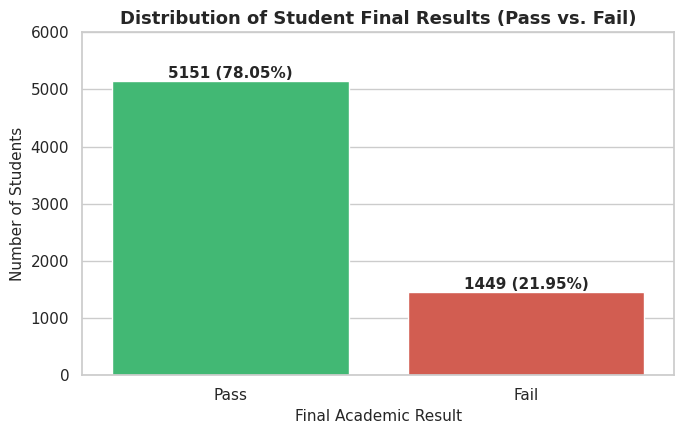

In [350]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
custom_palette = {"Pass": "#2ecc71", "Fail": "#e74c3c"}

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(
    data=df_cleaned,
    x="final_result",
    hue="final_result",
    palette=custom_palette,
    legend=False,
    ax=ax,
)

total = len(df_cleaned)
for p in ax.patches:
    count = int(p.get_height())
    percentage = f"{100 * count / total:.2f}%"
    ax.annotate(
        f"{count} ({percentage})",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )

ax.set_title(
    "Distribution of Student Final Results (Pass vs. Fail)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Final Academic Result", fontsize=11)
ax.set_ylabel("Number of Students", fontsize=11)
ax.set_ylim(0, 6000)
plt.tight_layout()
plt.show()

### **2.2: Visualization 2 (Attendance & Study Hours by Final Result)**



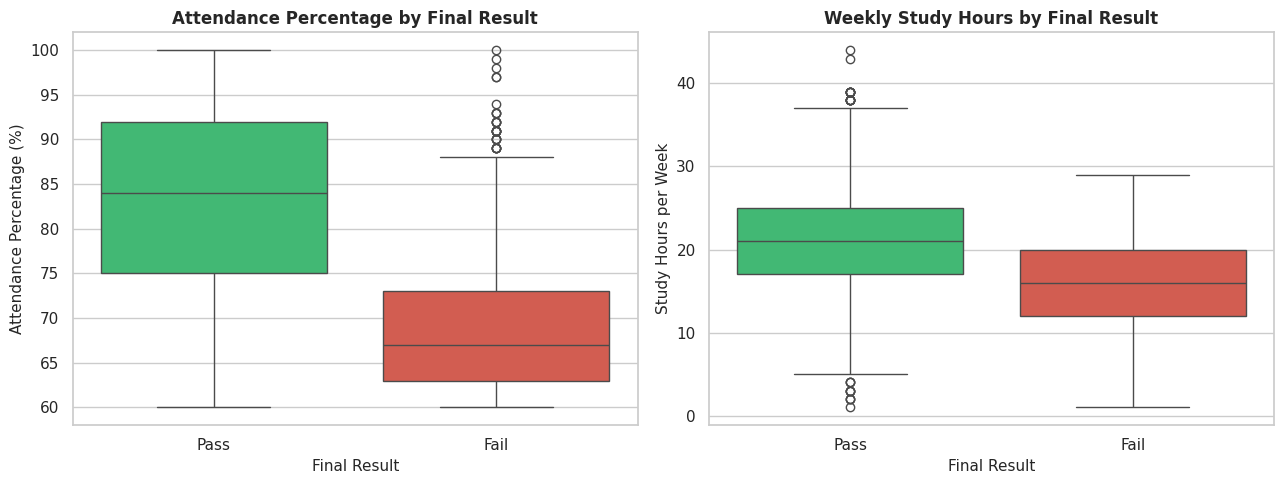

,study_hours,attendance,previous_score,assignments_completed,sleep_hours
final_result,,,,,
Fail,15.91,69.23,71.36,1.19,7.04
Pass,21.12,83.00,76.12,1.58,7.03


In [351]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df_cleaned,
    x="final_result",
    y="attendance",
    hue="final_result",
    palette=custom_palette,
    legend=False,
    ax=axes[0],
)
axes[0].set_title(
    "Attendance Percentage by Final Result",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Final Result", fontsize=11)
axes[0].set_ylabel("Attendance Percentage (%)", fontsize=11)

sns.boxplot(
    data=df_cleaned,
    x="final_result",
    y="study_hours",
    hue="final_result",
    palette=custom_palette,
    legend=False,
    ax=axes[1],
)
axes[1].set_title(
    "Weekly Study Hours by Final Result",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Final Result", fontsize=11)
axes[1].set_ylabel("Study Hours per Week", fontsize=11)

plt.tight_layout()
plt.show()

print("\n\n")
display(df_cleaned.groupby("final_result").mean().round(2))

### **2.3: Visualization 3 (Previous Score Distribution by Class)**

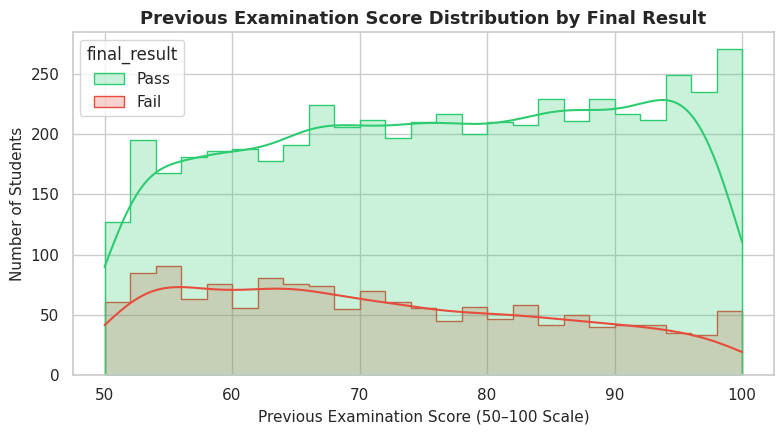

In [352]:
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.histplot(
    data=df_cleaned,
    x="previous_score",
    hue="final_result",
    kde=True,
    palette=custom_palette,
    element="step",
    bins=25,
    ax=ax,
)

ax.set_title(
    "Previous Examination Score Distribution by Final Result",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Previous Examination Score (50–100 Scale)", fontsize=11)
ax.set_ylabel("Number of Students", fontsize=11)
plt.tight_layout()
plt.show()

### **2.4: Visualization 4 (Correlation Heatmap of Numerical Features)**

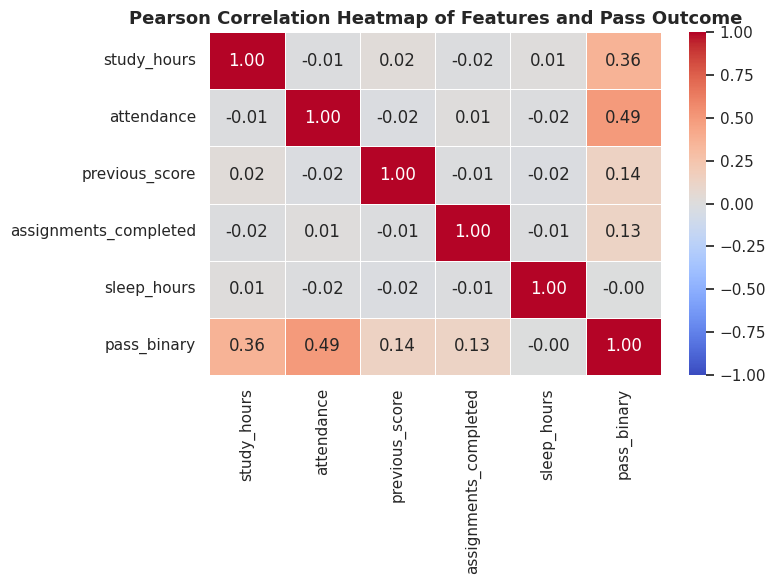

In [353]:
fig, ax = plt.subplots(figsize=(8, 6))

df_corr = df_cleaned.copy()
df_corr["pass_binary"] = (df_corr["final_result"] == "Pass").astype(int)

corr_matrix = df_corr.drop(columns=["final_result"]).corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax,
)

ax.set_title(
    "Pearson Correlation Heatmap of Features and Pass Outcome",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

### **2.5: Evidence-Based Observations & Dataset Limitations**

#### 1. Key Evidence-Based Observations from Charts:
- **Strong Positive Association with Attendance and Study Hours (Figures 2.1, 2.2 & 4):**  
  Students in the `Pass` group have a substantially higher average attendance (**83.00%**, median **84.0%**) compared to the `Fail` group (**69.23%**, median **67.0%**), yielding the highest positive correlation with passing ($r = 0.49$). Similarly, `Pass` students study an average of **21.12 hours/week** (median **21.0**) compared to **15.91 hours/week** (median **16.0**) for `Fail` students ($r = 0.36$).
- **Secondary Influence of Previous Scores and Extra Practice, and Near-Zero Linear Effect of Sleep Hours (Figures 3 & 4):**  
  `previous_score` ($r = 0.14$, mean **76.12** for `Pass` vs. **71.36** for `Fail`) and `assignments_completed` ($r = 0.13$, mean **1.58** vs. **1.19**) show modest positive correlations with passing. In contrast, `sleep_hours` shows virtually no linear difference between the two groups (mean **7.03 hrs** for `Pass` vs. **7.04 hrs** for `Fail`, $r = -0.004$).
- **Low Multicollinearity Among Input Features (Figure 4):**  
  Pairwise correlations between input features are near zero (all $|r| \le 0.03$), indicating that each feature provides independent information without severe multicollinearity—an ideal condition for Logistic Regression.

#### 2. Observed Patterns vs. Unestablished Causal Conclusions:
- **What we observe (Correlation):** Higher class attendance and longer weekly study hours are strongly associated with a higher likelihood of achieving a passing score ($\ge 65$).
- **What we cannot establish (Causation):** Because this is an observational dataset rather than a controlled experiment, we **cannot conclude** that simply forcing a student to sit in class longer or log more study hours will *cause* them to pass. Unmeasured confounding variables—such as teaching quality, student mental health, socioeconomic support, or learning disabilities—could simultaneously affect both attendance/study habits and exam performance.

#### 3. Class Imbalance and Dataset Limitations Affecting Evaluation:
- **Class Imbalance:** The dataset has a **78.05% (`Pass`) vs. 21.95% (`Fail`)** imbalance (roughly a **3.55 : 1** ratio). Because `Pass` is the majority class, a naive classifier that predicts `Pass` for every student would still achieve **78.05% accuracy** while failing to identify a single struggling student. Therefore, we must use **stratified train/test splitting** in Task 3 and prioritize **Precision, Recall, and F1-Score** (especially on the `Fail` / at-risk class) alongside Accuracy in Task 4.
- **Threshold & Proxy Limitations:** The target `final_result` was binarized at a score threshold of `65` (since the dataset's minimum `Exam_Score` is `55`), and `Tutoring_Sessions` was mapped as a proxy for `assignments_completed`. Consequently, students scoring `64` (`Fail`) and `65` (`Pass`) have very similar feature profiles near the decision boundary.

## **3: Train and Compare Machine Learning Models**

### **3.1 Define Features (X) and Target (y) & Create Reproducible Stratified Train/Test Split**

In [354]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Shape of X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Shape of  X_test  = {X_test.shape}, y_test  = {y_test.shape}\n")


Shape of X_train = (5280, 5), y_train = (5280,)
Shape of  X_test  = (1320, 5), y_test  = (1320,)



In [355]:
split_summary = pd.DataFrame(
    {
        "Train Count": y_train.value_counts(),
        "Train %": (y_train.value_counts(normalize=True) * 100).round(2),
        "Test Count": y_test.value_counts(),
        "Test %": (y_test.value_counts(normalize=True) * 100).round(2),
    }
)
print("class distribution across train and test sets")
display(split_summary)

class distribution across train and test sets


,Train Count,Train %,Test Count,Test %
final_result,,,,
Pass,4121,78.05,1030,78.03
Fail,1159,21.95,290,21.97


### **3.2: Feature Scaling & Model Training (Logistic Regression & KNN)**

In [356]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [357]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_cv_scores = cross_val_score(
    lr_model, X_train_scaled, y_train, cv=cv, scoring="accuracy"
)
print("Logistic Regression CV Accuracy:", lr_cv_scores.mean()*100)

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
print(f"Logistic Regression Accuracy:", lr_accuracy*100)

print("\n Logistic Regression Predictions:")
print(pd.Series(y_pred_lr).value_counts())


Logistic Regression CV Accuracy: 89.20454545454545
Logistic Regression Accuracy: 88.93939393939394

 Logistic Regression Predictions:
Pass    1062
Fail     258
Name: count, dtype: int64


In [358]:
from sklearn.neighbors import KNeighborsClassifier


knn_cv_scores = cross_val_score(
    knn_model, X_train_scaled, y_train, cv=cv, scoring="accuracy"
)
print("KNN CV Accuracy:", knn_cv_scores.mean()*100)

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
print(f"KNN Accuracy:", knn_accuracy*100)

print("\n KNN Predictions:")
print(pd.Series(y_pred_knn).value_counts())

KNN CV Accuracy: 87.78409090909089
KNN Accuracy: 86.36363636363636

 KNN Predictions:
Pass    1072
Fail     248
Name: count, dtype: int64


### **3.3 How Logistic Regression and KNN Make Predictions & Why They Are Suitable Baselines**



1. **Logistic Regression:**
   - **Working:** Computes a weighted sum of input features ($z = w^T x + b$) and passes it through the Sigmoid function to generate a probability of passing ($0$ to $1$). If probability $\ge 0.5$, it predicts `Pass`.
   - **Why suitable:** Our EDA showed strong monotonic linear relationships between attendance/study hours and exam results. It provides fast training, interpretable coefficients, and calibrated probabilities.

2. **K-Nearest Neighbors (KNN):**
   - **Working:** A non-parametric, distance-based algorithm. For each test student, it measures Euclidean distance to all training samples and predicts the class by majority vote among the $k = 5$ closest neighbors.
   - **Why suitable:** It makes no linear assumptions and captures local neighborhood patterns, serving as an ideal non-linear benchmark against Logistic Regression.

## **4: Model Evaluation and Interpretation**

### **4.1 Model Evaluation Metrics and Comparison Table**

In [359]:
from sklearn.metrics import classification_report

print("--- CLASSIFICATION REPORT: LOGISTIC REGRESSION ---")
print(classification_report(y_test, y_pred_lr, digits=4))

--- CLASSIFICATION REPORT: LOGISTIC REGRESSION ---
              precision    recall  f1-score   support

        Fail     0.7791    0.6931    0.7336       290
        Pass     0.9162    0.9447    0.9302      1030

    accuracy                         0.8894      1320
   macro avg     0.8476    0.8189    0.8319      1320
weighted avg     0.8861    0.8894    0.8870      1320



In [360]:
from sklearn.metrics import classification_report

print("--- CLASSIFICATION REPORT: KNN ---")
print(classification_report(y_test, y_pred_knn, digits=4))

--- CLASSIFICATION REPORT: KNN ---
              precision    recall  f1-score   support

        Fail     0.7218    0.6172    0.6654       290
        Pass     0.8965    0.9330    0.9144      1030

    accuracy                         0.8636      1320
   macro avg     0.8091    0.7751    0.7899      1320
weighted avg     0.8581    0.8636    0.8597      1320



In [361]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

def get_metrics(model_name, y_pred):
    return {
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, pos_label="Pass"), 4),
        "Recall": round(recall_score(y_test, y_pred, pos_label="Pass"), 4),
        "F1-Score": round(f1_score(y_test, y_pred, pos_label="Pass"), 4),
    }


comparison_df = pd.DataFrame(
    [
        get_metrics("Logistic Regression", y_pred_lr),
        get_metrics("K-Nearest Neighbors (KNN)", y_pred_knn),
    ]
)

print("--- MODEL COMPARISON TABLE ---")
display(comparison_df)

--- MODEL COMPARISON TABLE ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8894,0.9162,0.9447,0.9302
1,K-Nearest Neighbors (KNN),0.8636,0.8965,0.9330,0.9144


### **4.2 Confusion Matrices for Logistic Regression and KNN**

Below are the confusion matrices on the held-out test set (`1,030 Actual Pass` and `290 Actual Fail` students), with clearly labeled axes showing `Actual` vs. `Predicted` outcomes.

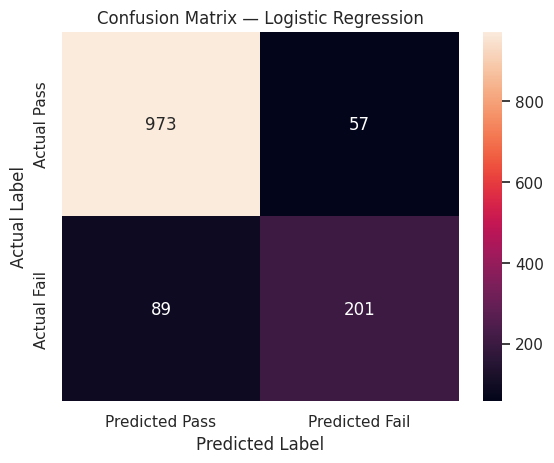

In [362]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr, labels=["Pass", "Fail"])

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    xticklabels=["Predicted Pass", "Predicted Fail"],
    yticklabels=["Actual Pass", "Actual Fail"],
)

plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

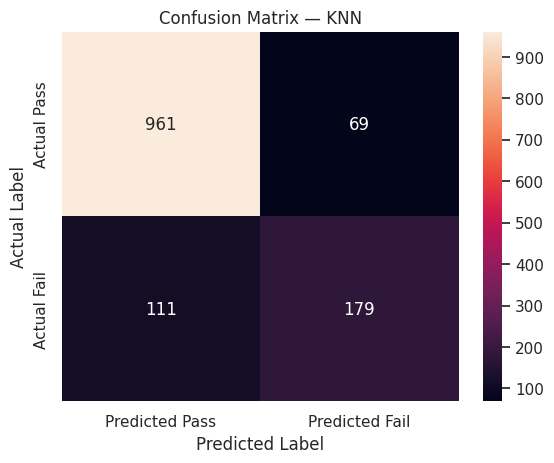

In [363]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_knn = confusion_matrix(y_test, y_pred_knn, labels=["Pass", "Fail"])

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    xticklabels=["Predicted Pass", "Predicted Fail"],
    yticklabels=["Actual Pass", "Actual Fail"],
)

plt.title("Confusion Matrix — KNN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### **4.3 Save the Selected Model Pipeline for Deployment**

In [364]:
import os
import joblib

os.makedirs("models", exist_ok=True)
joblib.dump(
    {"model": lr_model, "scaler": scaler}, "models/model_pipeline.joblib"
)
print("Model saved successfully to 'models/model_pipeline.joblib'")


Model saved successfully to 'models/model_pipeline.joblib'


### **4.4 Written Interpretation of Evaluation Results**

#### 1. Model Selection and Justification (Beyond Accuracy Alone)
We select **Logistic Regression** over **KNN ($k=5$)** as our final model for the following reasons:
- **Superior Performance on Both Majority (`Pass`) and Minority (`Fail`) Classes:**  
  Alongside higher overall Accuracy (**88.94%** vs. **86.36%**), Logistic Regression achieves a higher F1-Score on the `Pass` class (**0.9302** vs. **0.9144**) and a substantially stronger F1-Score on the minority `Fail` class (**0.7336** vs. **0.6654**).
- **Higher Recall for At-Risk Students (`Fail` Class):**  
  In a student-support context, catching struggling students is critical. Logistic Regression correctly identifies **201 out of 290** failing students (**69.31% Recall on `Fail`**), whereas KNN only identifies **179 out of 290** (**61.72% Recall on `Fail`**), missing 22 additional struggling students.
- **Interpretability and Calibrated Probabilities:**  
  Logistic Regression provides clear feature weights (`attendance = +2.38`, `study_hours = +1.64`, `previous_score = +0.69`, `assignments_completed = +0.60`), allowing teachers to understand *why* a student is flagged, and outputs smooth probability estimates rather than discretized $k/5$ fractions.

#### 2. Meaning of False Positives and False Negatives in the Student-Support Scenario
*(Using `Pass` as the Positive Class, as ordered in the Confusion Matrix)*:
- **True Positive (`Actual = Pass, Predicted = Pass` — LR: 973, KNN: 961):** Students who are on track to pass and are correctly predicted to pass.
- **True Negative (`Actual = Fail, Predicted = Fail` — LR: 201, KNN: 179):** At-risk students who will fail without help and are **correctly flagged** by the model for extra academic support.
- **False Positive (`Actual = Fail, Predicted = Pass` — LR: 89, KNN: 111):** A student who is actually struggling and goes on to **Fail**, but the model mistakenly predicts they will **Pass**. **Practical Impact:** This is the **most harmful error** in a student-support scenario because an at-risk student goes unnoticed and misses out on timely tutoring or remedial intervention.
- **False Negative (`Actual = Pass, Predicted = Fail` — LR: 57, KNN: 69):** A student who would actually **Pass**, but the model mistakenly flags them as likely to **Fail**. **Practical Impact:** This error is much less harmful—the student may receive extra check-ins or support resources they did not strictly need, which incurs minor resource overhead for the school but does not hurt the student academically. *(Note: If `Fail` is defined as the positive class for intervention, these two error labels swap names, but the real-world consequence of missing an at-risk student remains the primary concern).*

#### 3. Why Accuracy Alone Can Be Misleading with Imbalanced Classes
In our dataset, **78.05%** of students belong to the `Pass` class and only **21.95%** belong to the `Fail` class. If a flawed model simply predicted `Pass` for every single student without learning anything, it would still achieve **78.03% test accuracy**—yet it would have **0% Recall on `Fail`**, completely failing the school's objective of identifying struggling students. Therefore, evaluating class-specific **Precision, Recall, and F1-Score** alongside the Confusion Matrix is essential.

#### 4. Key Limitations of the Evaluation
1. **Binarized Target Threshold Boundary Effects:** Because `final_result` was derived from a continuous `Exam_Score` using a hard threshold of `65`, students scoring `64` (`Fail`) and `65` (`Pass`) have virtually identical study habits and attendance, creating unavoidable overlap near the decision boundary.
2. **Lack of External Validation Across Different Schools:** Both training and test sets come from a single static dataset. Without external validation on data from different academic years, curricula, or schools, we cannot guarantee that the exact `65`-point threshold or learned weights generalize universally.
3. **Ethical Note on Educational Decision-Making:** Predictions from this model must **never** be used as the sole basis for grading, tracking, or penalizing students; they should only serve as an early-warning indicator to help educators offer supportive check-ins.

## **5: Build and Test a Prediction Interface**

### **5.1 Load Saved Pipeline & Define Validated Prediction Function**

### **5.2 Testing the Prediction Interface with Sample Student Profiles**

In [371]:
import joblib
import pandas as pd

saved_objects = joblib.load("models/model_pipeline.joblib")
model = saved_objects["model"]
scaler = saved_objects["scaler"]

def predict_student(
    study_hours, attendance, previous_score, assignments_completed, sleep_hours
):
  if not (0 <= attendance <= 100):
    raise ValueError("attendance must be between 0% and 100%.")
  if not (0 <= previous_score <= 100):
    raise ValueError("previous_score must be between 0 and 100.")
  if assignments_completed < 0:
    raise ValueError("assignments_completed cannot be negative.")
  if not (0 <= study_hours <= 60):
    raise ValueError("study_hours must be between 0 and 60 hours/week.")
  if not (1 <= sleep_hours <= 16):
    raise ValueError("sleep_hours must be between 1 and 16 hours/day.")

  input_df = pd.DataFrame([{
      "study_hours": study_hours,
      "attendance": attendance,
      "previous_score": previous_score,
      "assignments_completed": assignments_completed,
      "sleep_hours": sleep_hours,
  }])

  input_scaled = scaler.transform(input_df)

  pred_class = model.predict(input_scaled)[0]
  pass_prob = round(model.predict_proba(input_scaled)[0][1] * 100, 2)

  return {
      "study_hours": study_hours,
      "attendance (%)": attendance,
      "previous_score": previous_score,
      "assignments_completed": int(assignments_completed),
      "sleep_hours": sleep_hours,
      "Predicted Class": pred_class,
      "Est. Pass Prob (%)": pass_prob,
      "Est. Fail Prob (%)": round(100 - pass_prob, 2),
      "Note": "Statistical model estimate only (not a guaranteed outcome).",
  }

print("prediction 1:")
print(predict_student(25.0, 90.0, 82.0, 3, 7.5))

print("\nprediction 2:")
print(predict_student(10.0, 62.0, 55.0, 0, 6.0))


prediction 1:
{'study_hours': 25.0, 'attendance (%)': 90.0, 'previous_score': 82.0, 'assignments_completed': 3, 'sleep_hours': 7.5, 'Predicted Class': 'Pass', 'Est. Pass Prob (%)': np.float64(99.98), 'Est. Fail Prob (%)': np.float64(0.02), 'Note': 'Statistical model estimate only (not a guaranteed outcome).'}

prediction 2:
{'study_hours': 10.0, 'attendance (%)': 62.0, 'previous_score': 55.0, 'assignments_completed': 0, 'sleep_hours': 6.0, 'Predicted Class': 'Fail', 'Est. Pass Prob (%)': np.float64(0.13), 'Est. Fail Prob (%)': np.float64(99.87), 'Note': 'Statistical model estimate only (not a guaranteed outcome).'}
